# M2 — Dimensionality reduction (linear + non-linear) and clustering
**Owner:** Nour Ashry (M2) · Rubric items 3 (after-reduction/clustering plots), 4 (linear, 1 mark), 5 (non-linear, 6 marks)

Inputs are M1's frozen artifacts in `results/data/` (131 hand-crafted features, 6 classes, shared splits and the 2,000-record training subsample). The 20% test set is never used here.

The heavy computation lives in two scripts so it is reproducible from the command line; this notebook runs them (optionally) and presents the results.
* `scripts/run_m2_embeddings.py`: linear analysis, 15 2D embeddings, k-means/GMM clustering, structure scores, hyper-parameter sweeps (~8 min on 2 CPUs)
* `scripts/run_m2_downstream.py`: group-1 reducers inside the classifier pipeline, 5-fold CV (~25 min)
* `src/reduction.py`: SNE from scratch, method registry, `ClipZ`, metrics, `best_reducer()` hand-off

In [1]:
import sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.loaders import FIG_DIR, MODELS_DIR
M2 = MODELS_DIR / "m2"
RERUN = False          # set True to recompute everything
if RERUN:
    for s in ["run_m2_embeddings.py", "run_m2_downstream.py"]:
        subprocess.run([sys.executable, str(ROOT / "scripts" / s)], check=True)

## 1. Preprocessing before any reduction
Median imputation → standardisation (both fit on the training 80% only) → **winsorise at ±5 sd** (`ClipZ`, stateless).
Why: max |z| in the training set is 68; only 0.14% of cells exceed 5 sd but they touch 5.8% of records. Without clipping, PCA, SVD, polynomial Kernel PCA, modified LLE and both MDS variants squeeze 99% of the points into a single blob. The "before" figure is kept for the report:

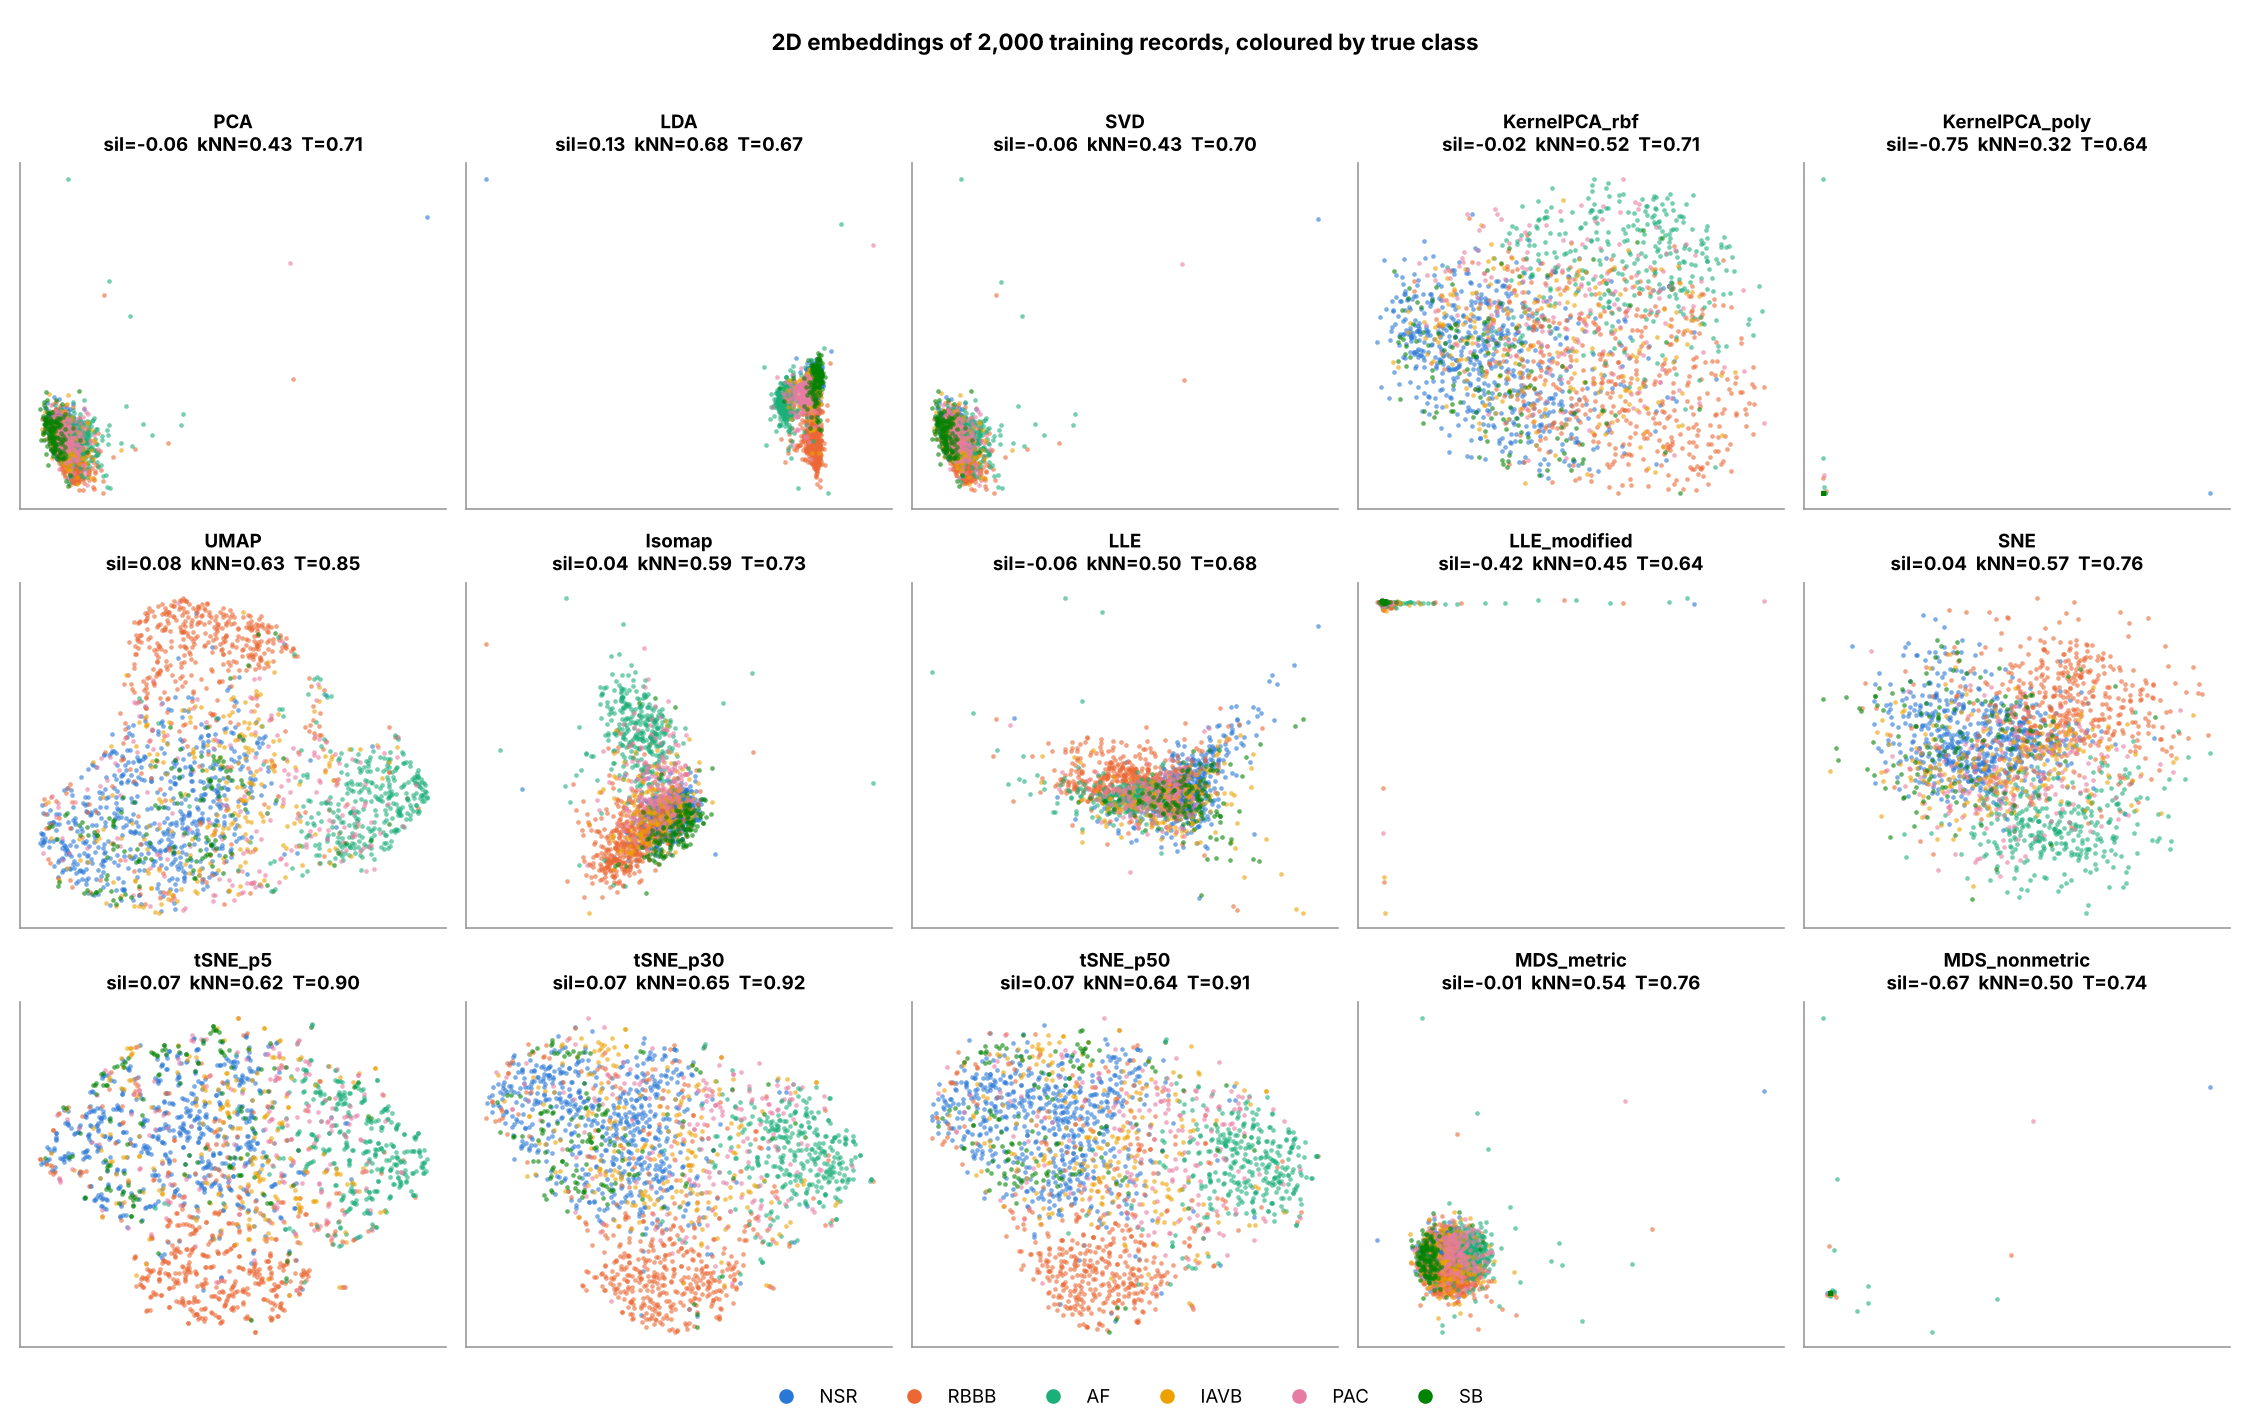

In [2]:
display(Image(FIG_DIR / "m2_unclipped" / "23_embeddings_true_class_unclipped.png", width=900))

## 2. Linear methods
### PCA: scree, cumulative variance, loadings

PC1+PC2 explain 23.9% of variance; 95% needs 45 of 131 components


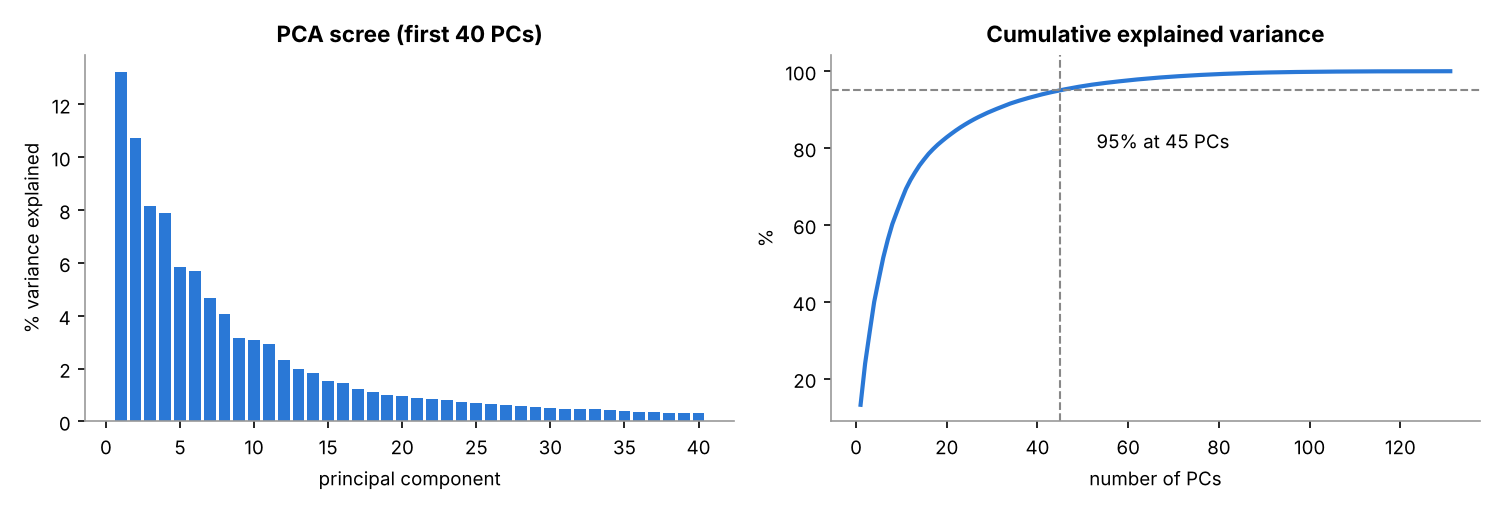

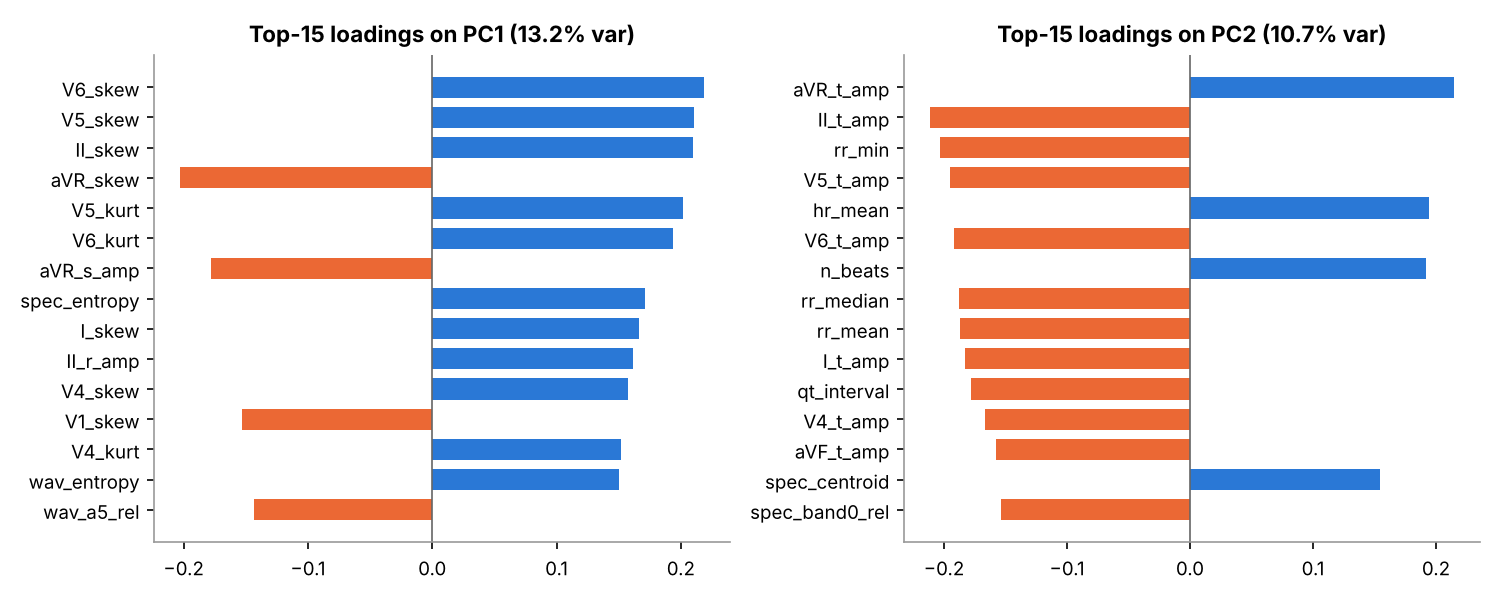

In [3]:
v = pd.read_csv(M2 / "pca_variance.csv"); n95 = int((v.cumulative < 0.95).sum() + 1)
print(f"PC1+PC2 explain {v.cumulative[1]*100:.1f}% of variance; 95% needs {n95} of 131 components")
display(Image(FIG_DIR / "20_pca_scree.png", width=850)); display(Image(FIG_DIR / "21_pca_loadings.png", width=850))

### Truncated SVD vs PCA
On standardised (centred) data SVD = PCA (same singular vectors, σᵢ² = (n−1)λᵢ). On uncentred data the first singular vector just points at the mean, which shows why centring matters.

,component,pca_explained,svd_centred_explained,svd_centred_singular,svd_uncentred_explained,svd_uncentred_singular
0,1,0.1323,0.1323,269.3585,0.0213,2672.9448
1,2,0.1072,0.1072,242.5334,0.1210,257.7408
2,3,0.0815,0.0815,211.4801,0.1062,241.3830
3,4,0.0789,0.0789,208.0148,0.0812,211.0841
4,5,0.0584,0.0584,179.0423,0.0786,207.6143
5,6,0.0568,0.0568,176.5434,0.0583,178.9116
6,7,0.0466,0.0466,159.9129,0.0564,175.9135
7,8,0.0406,0.0406,149.2871,0.0466,159.8592


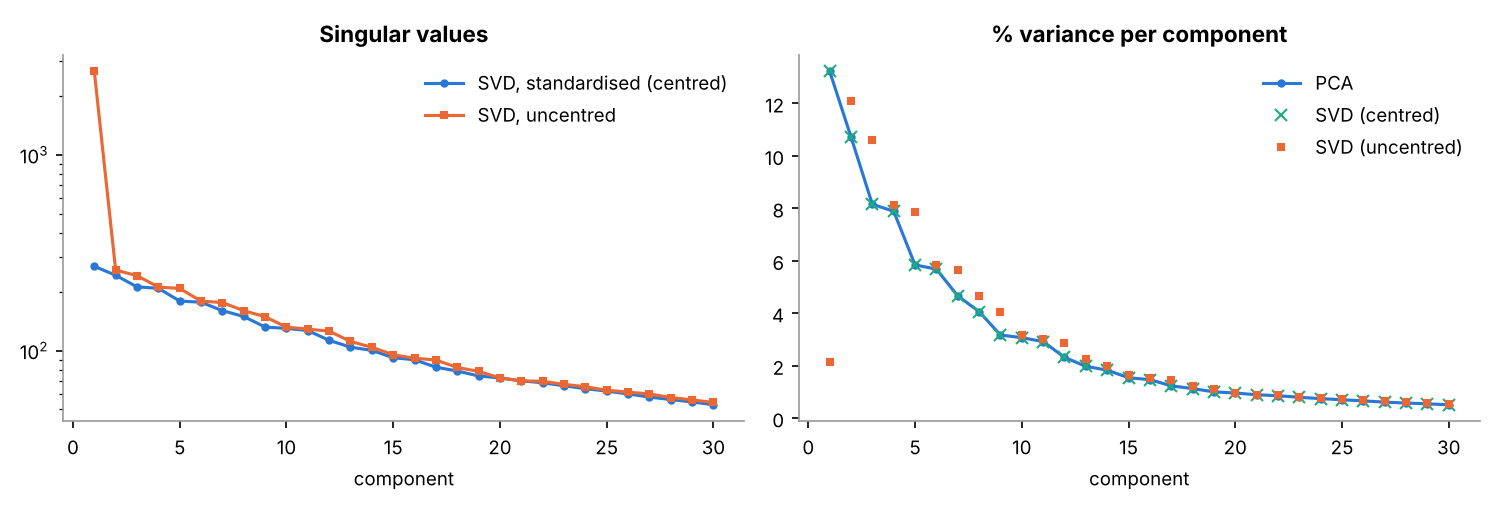

In [4]:
display(pd.read_csv(M2 / "svd_vs_pca.csv").head(8).round(4)); display(Image(FIG_DIR / "22_svd_vs_pca.png", width=850))

## 3. All methods: 2D embeddings of the shared subsample
Group 1 (has `transform`): PCA, LDA, SVD, Kernel PCA (RBF, poly), UMAP, Isomap, LLE (standard, modified). Group 2 (no out-of-sample mapping, plot only): SNE (from scratch), t-SNE (perplexity 5/30/50), metric MDS, non-metric MDS. LDA is fit on training records *outside* the subsample so its plot is not in-sample.

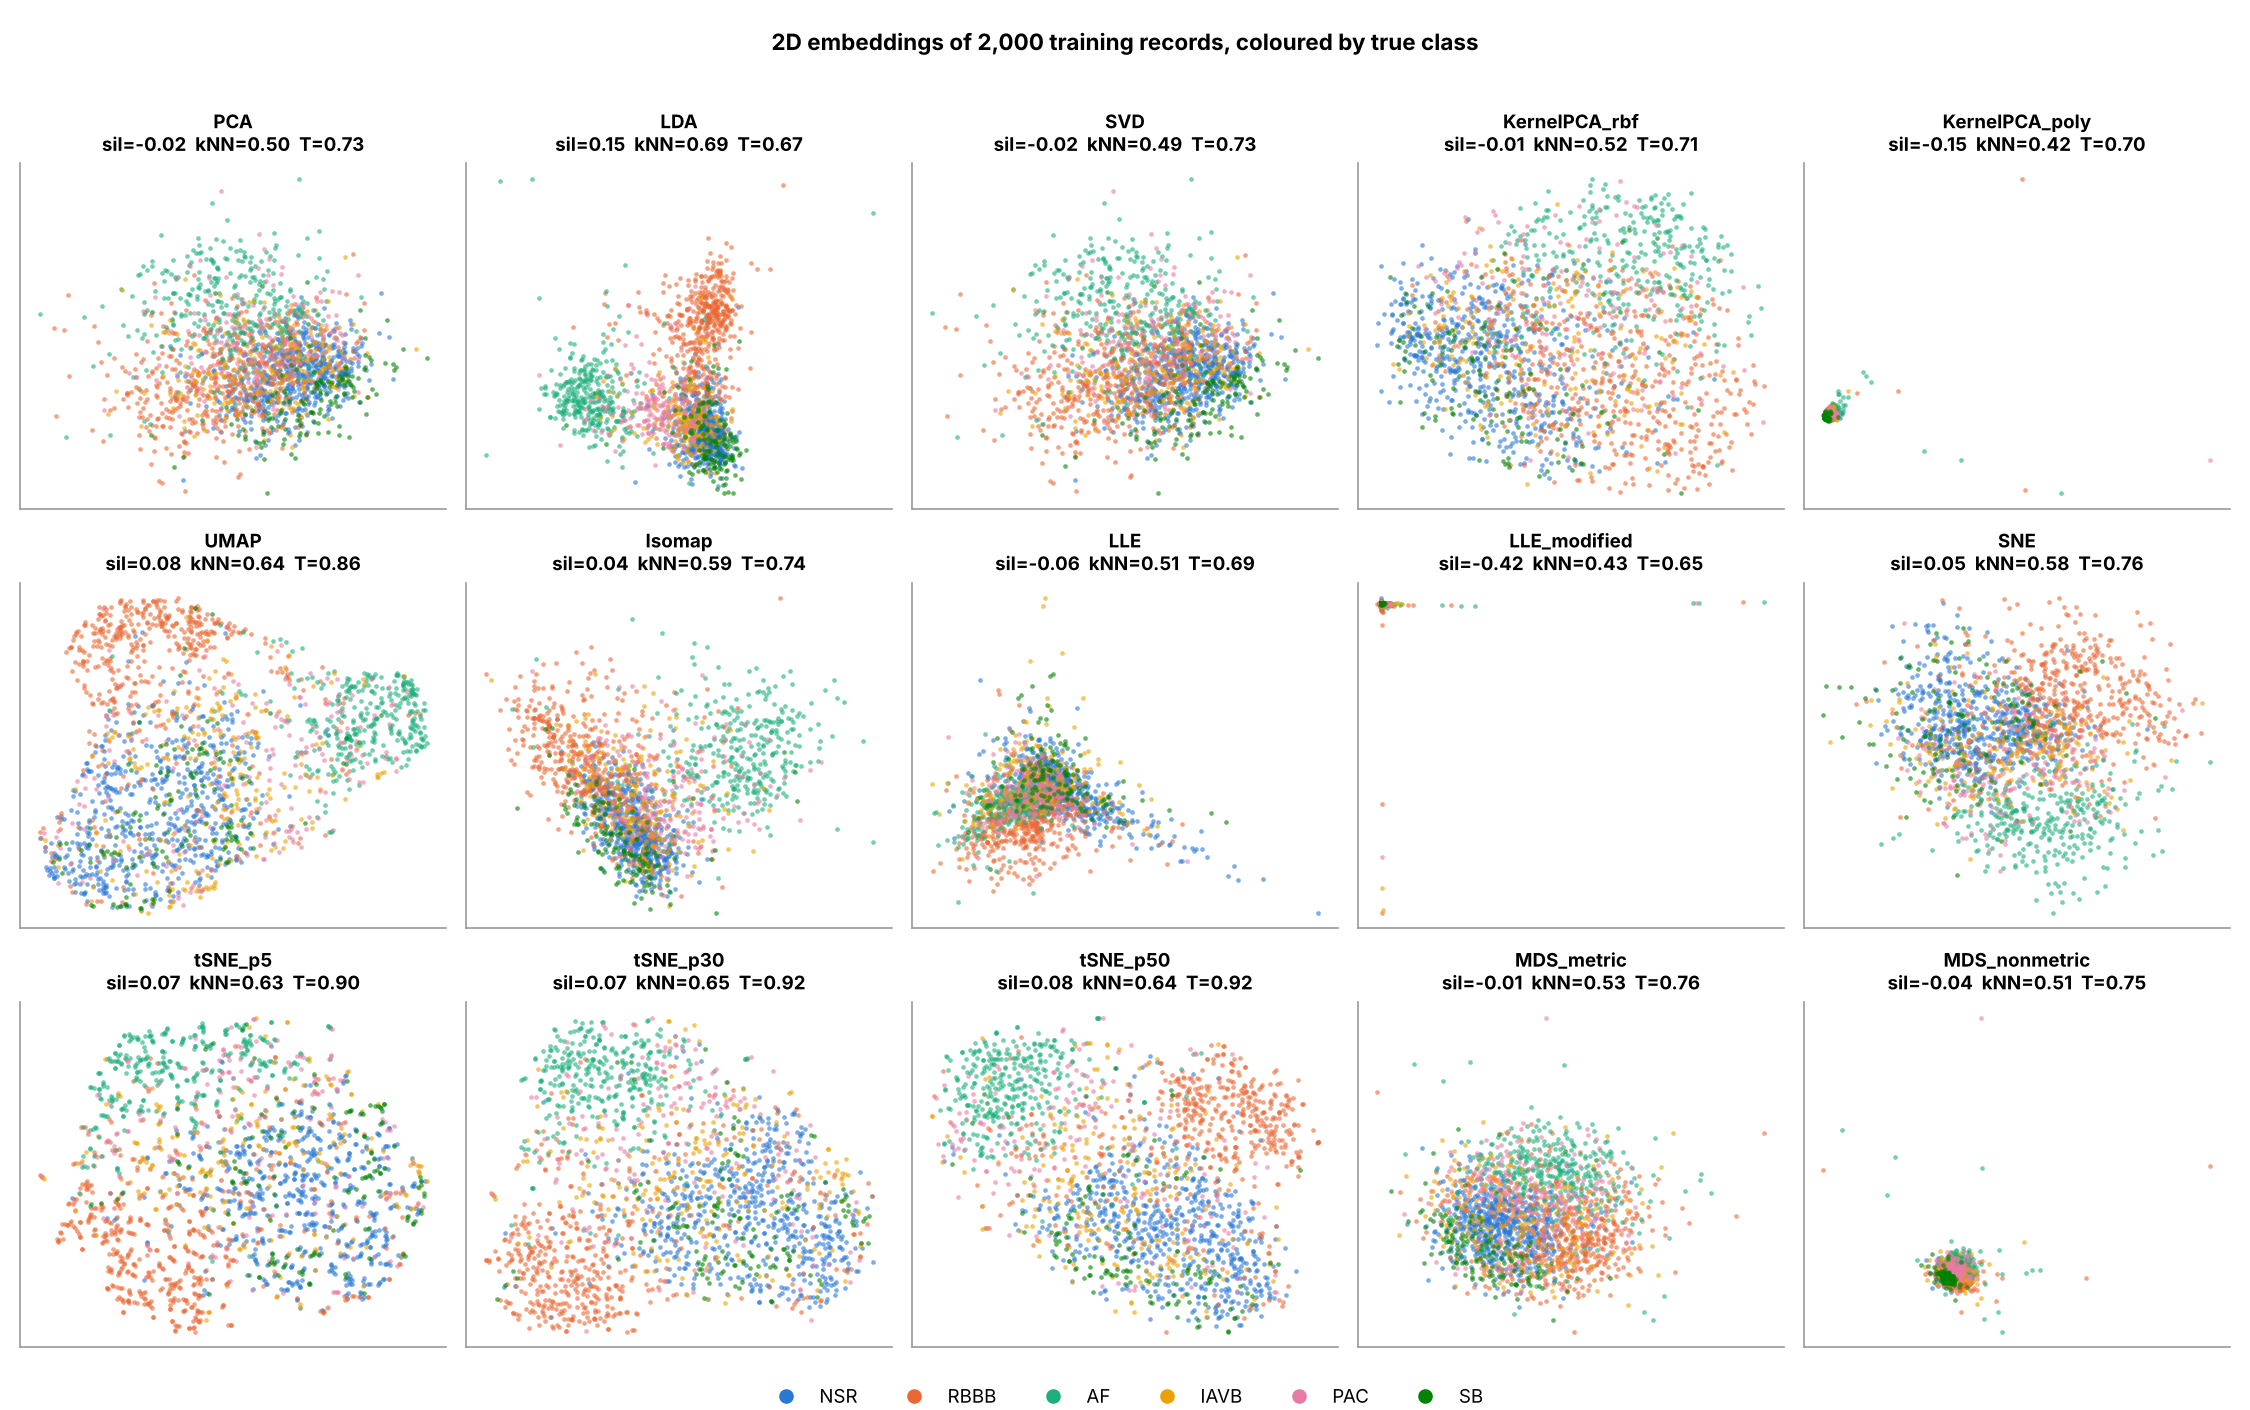

In [5]:
display(Image(FIG_DIR / "23_embeddings_true_class.png", width=1000))

In [6]:
sc = pd.read_csv(M2 / "embedding_scores.csv").set_index("method")
sc.drop(columns=["n_points"]).round(3).sort_values("knn_acc_2d", ascending=False)

,group,runtime_s,trustworthiness,silhouette_true,knn_acc_2d,knn_f1_2d,ari_kmeans,nmi_kmeans,ari_gmm,nmi_gmm
method,,,,,,,,,,
LDA,1,0.070,0.668,0.147,0.690,0.583,0.410,0.447,0.436,0.458
tSNE_p30,2,5.714,0.920,0.070,0.648,0.528,0.289,0.311,0.292,0.313
UMAP,1,11.903,0.860,0.082,0.638,0.501,0.291,0.312,0.259,0.297
tSNE_p50,2,6.509,0.915,0.077,0.637,0.516,0.290,0.325,0.302,0.328
tSNE_p5,2,4.759,0.901,0.067,0.628,0.492,0.235,0.268,0.235,0.281
Isomap,1,1.005,0.738,0.035,0.588,0.442,0.200,0.280,0.222,0.296
SNE,2,44.929,0.763,0.048,0.584,0.436,0.196,0.267,0.195,0.269
MDS_metric,2,8.753,0.763,-0.008,0.528,0.385,0.145,0.192,0.163,0.202
KernelPCA_rbf,1,0.123,0.711,-0.015,0.519,0.349,0.169,0.211,0.178,0.227


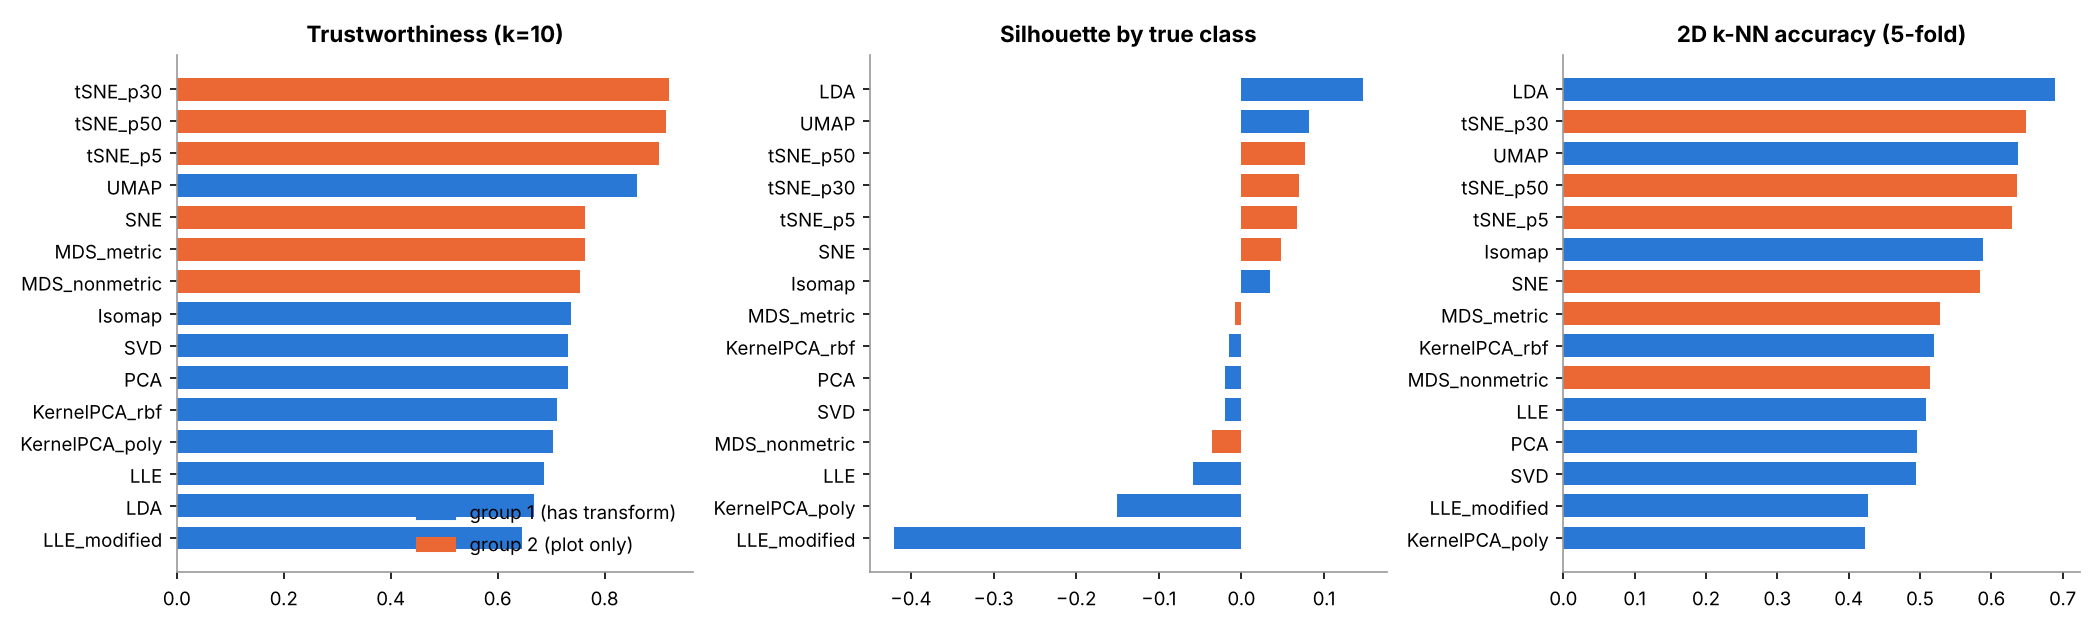

In [7]:
display(Image(FIG_DIR / "27_structure_scores.png", width=1000))

## 4. Clustering after reduction (k-means k=6 and GMM): true class vs clusters

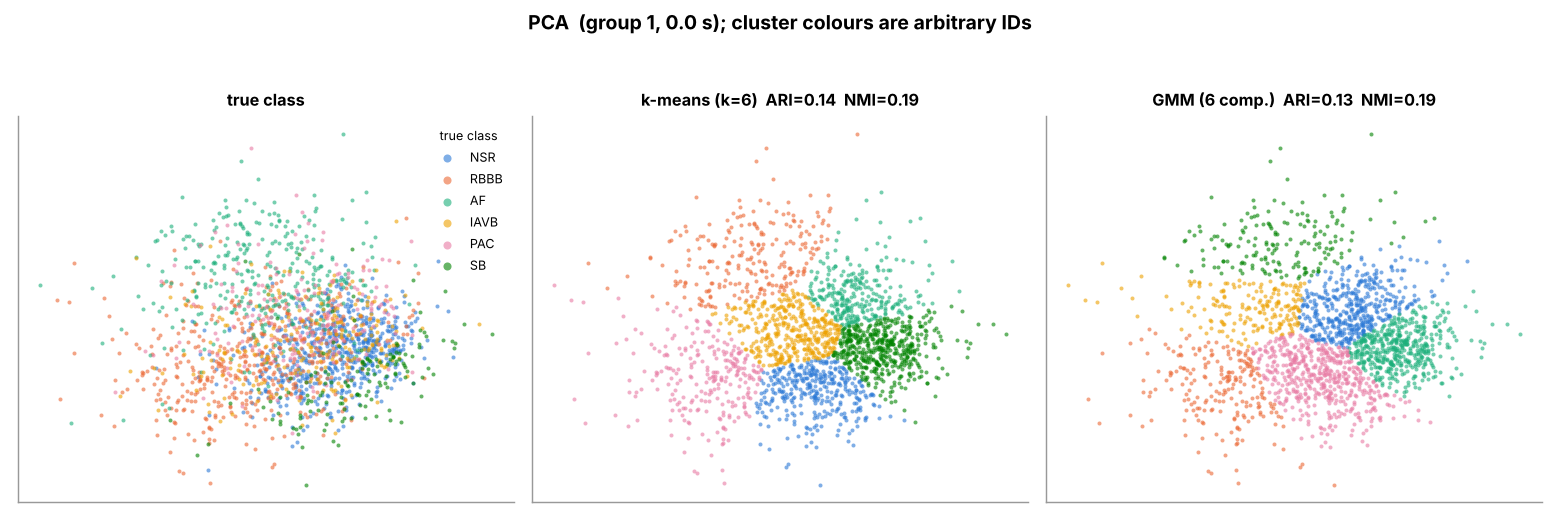

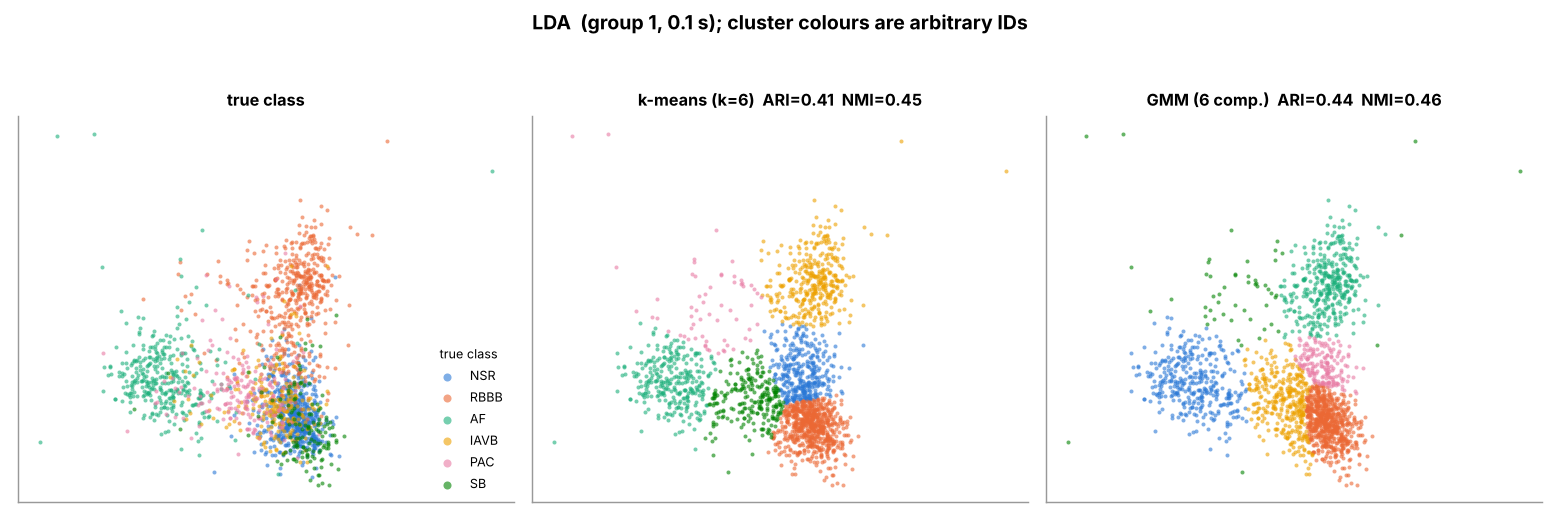

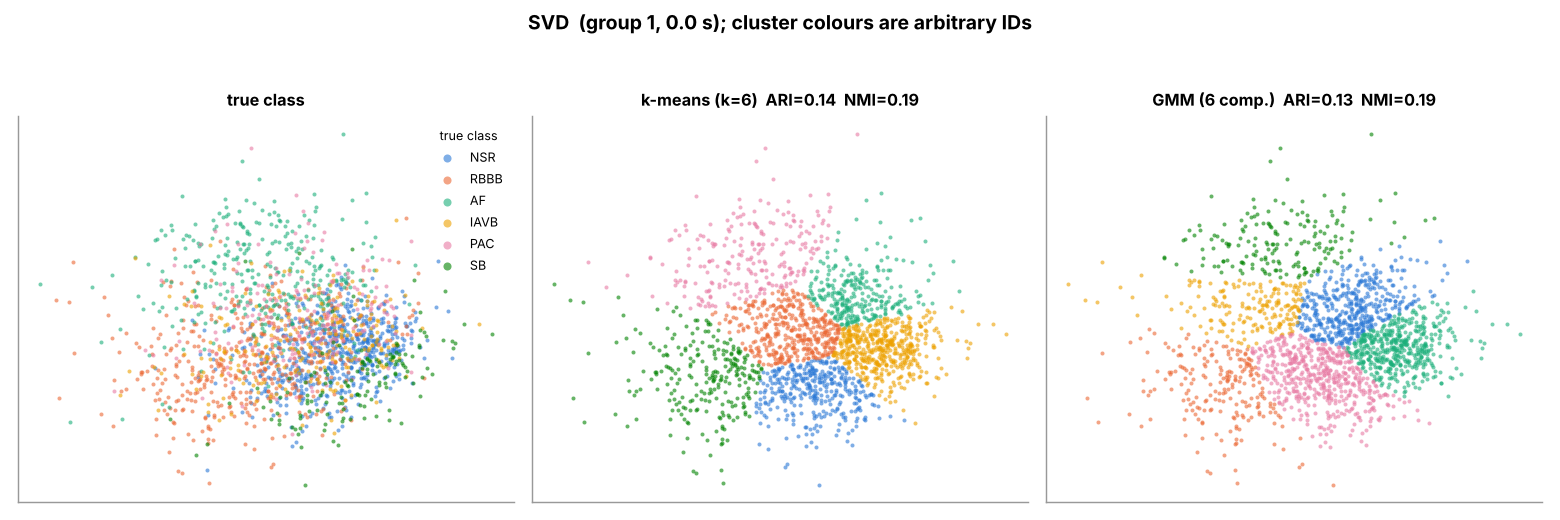

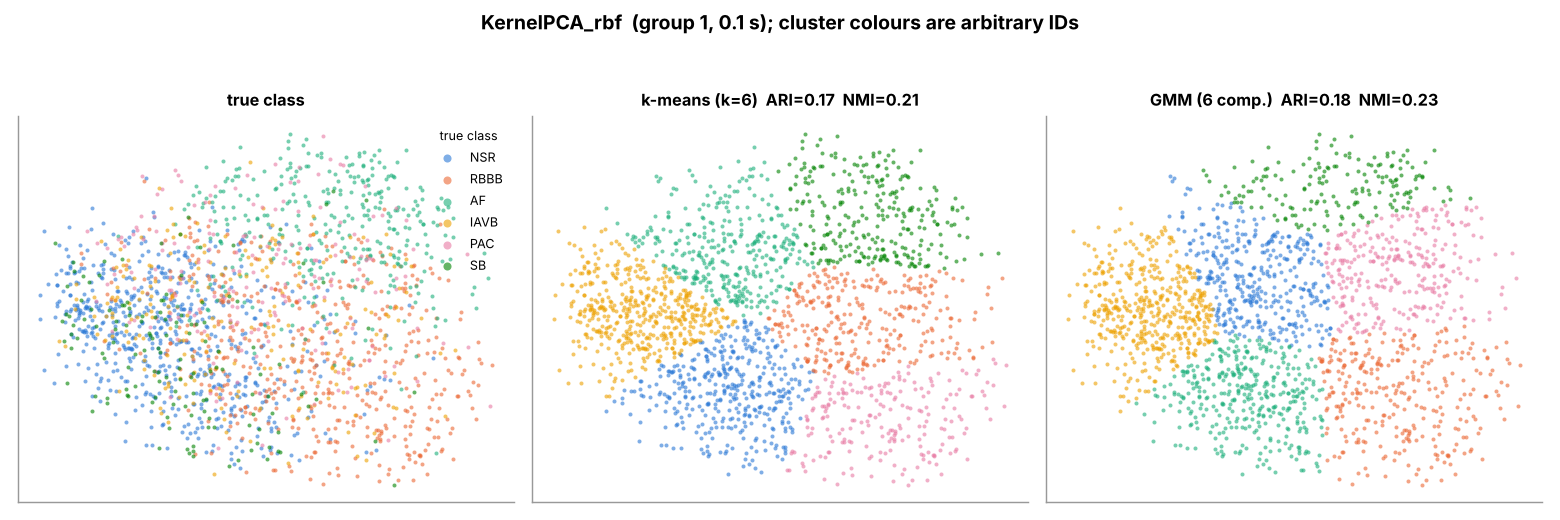

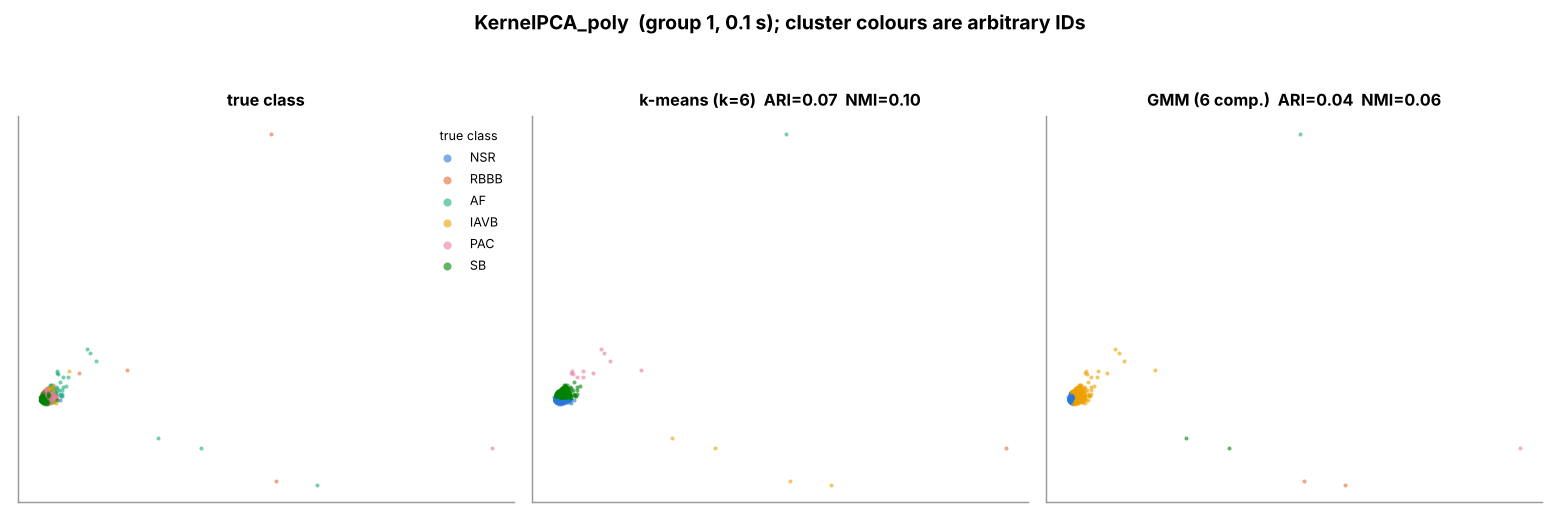

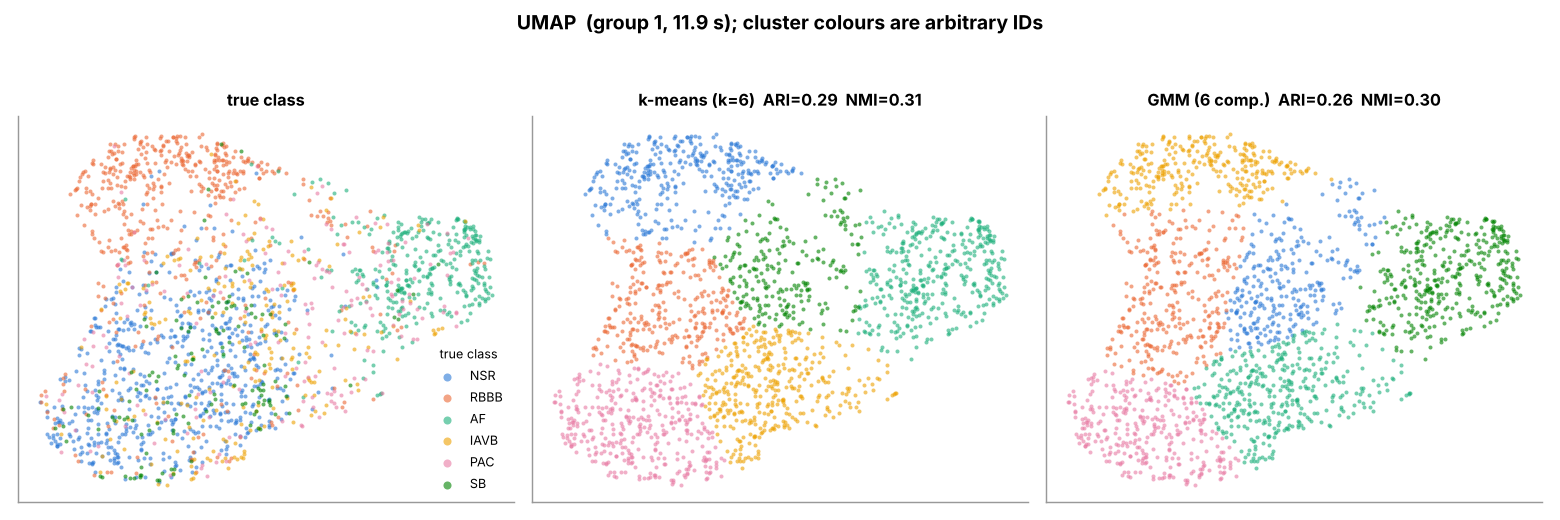

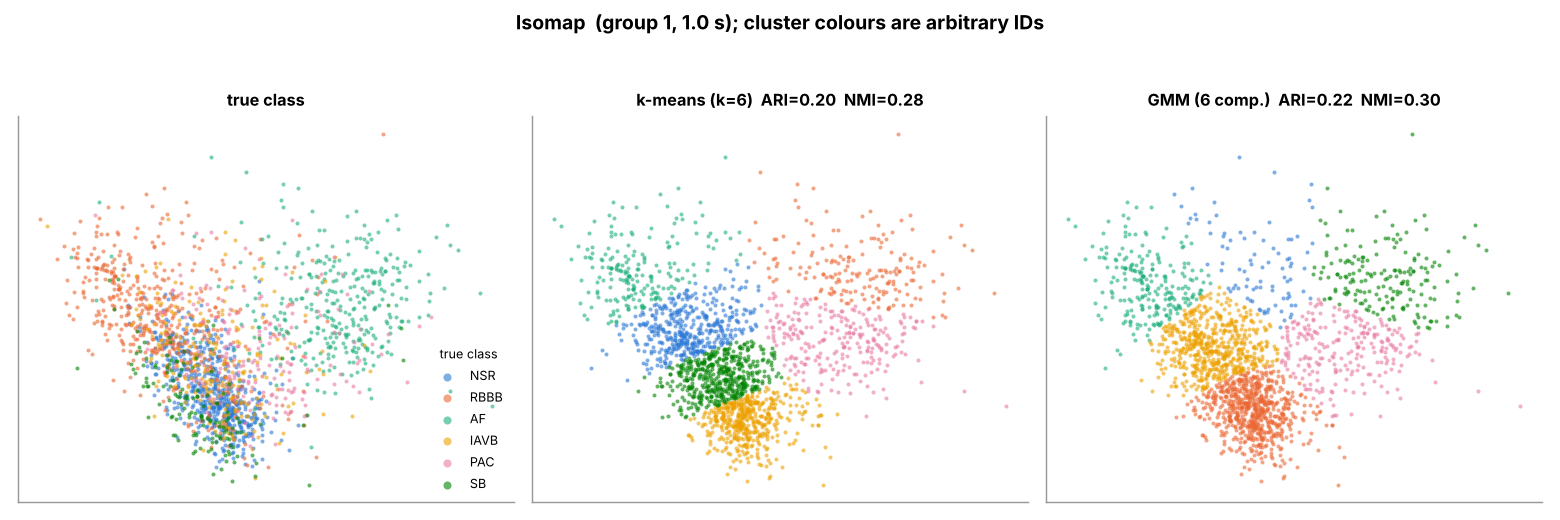

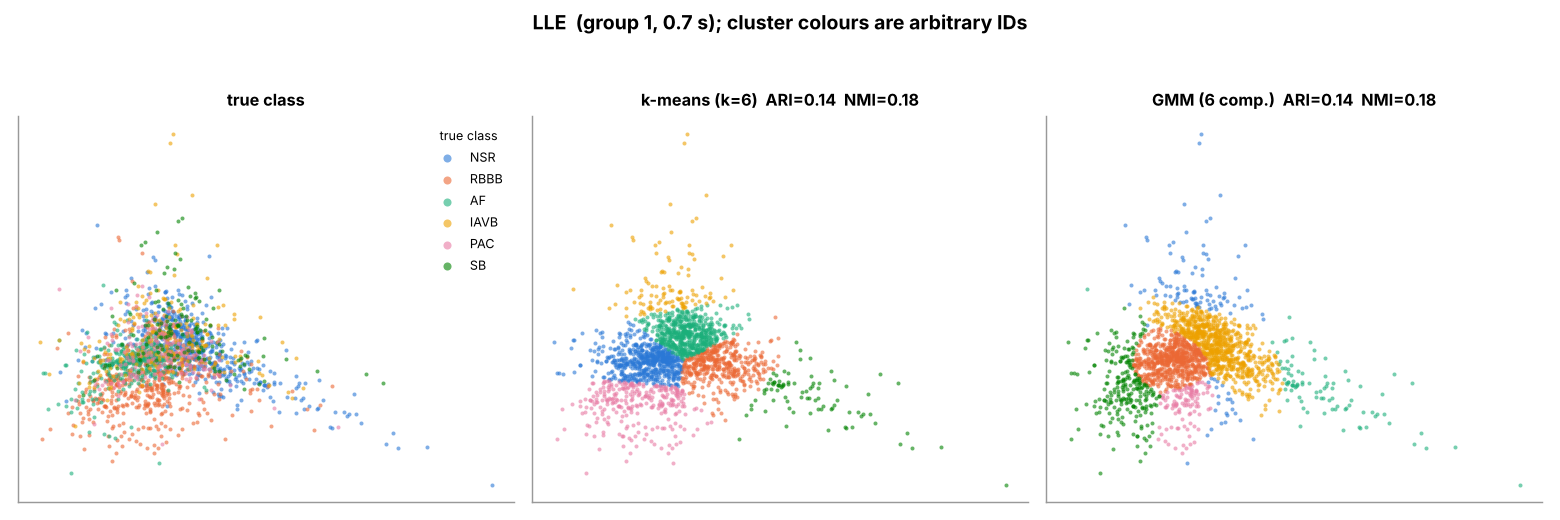

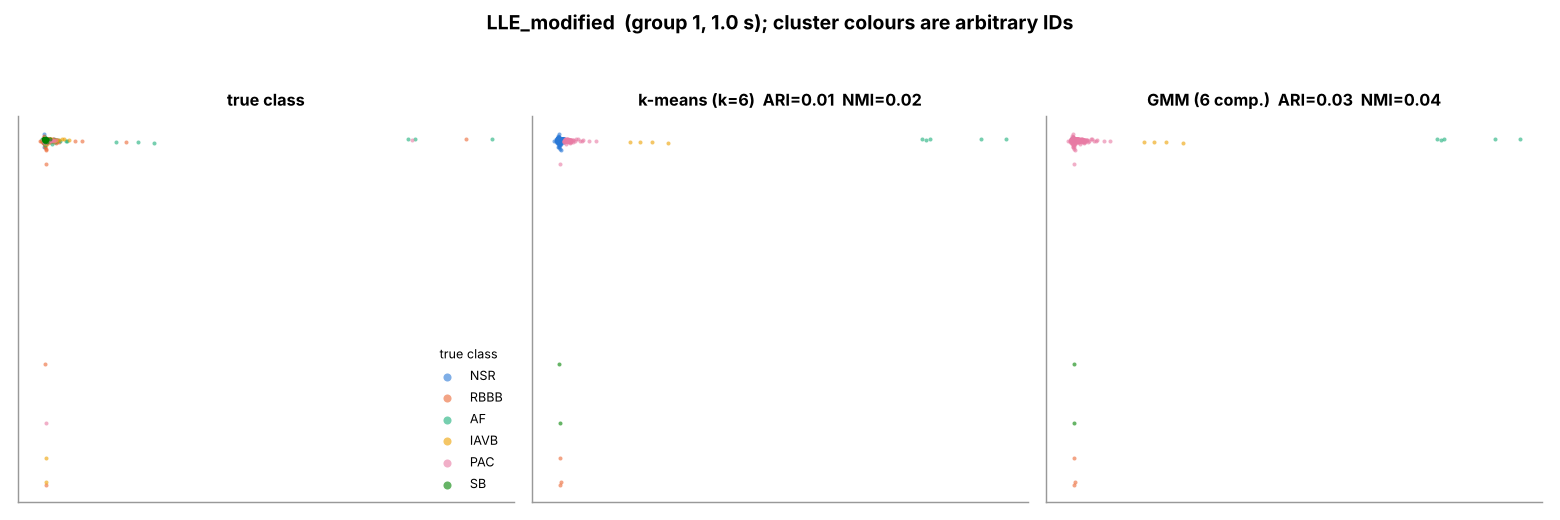

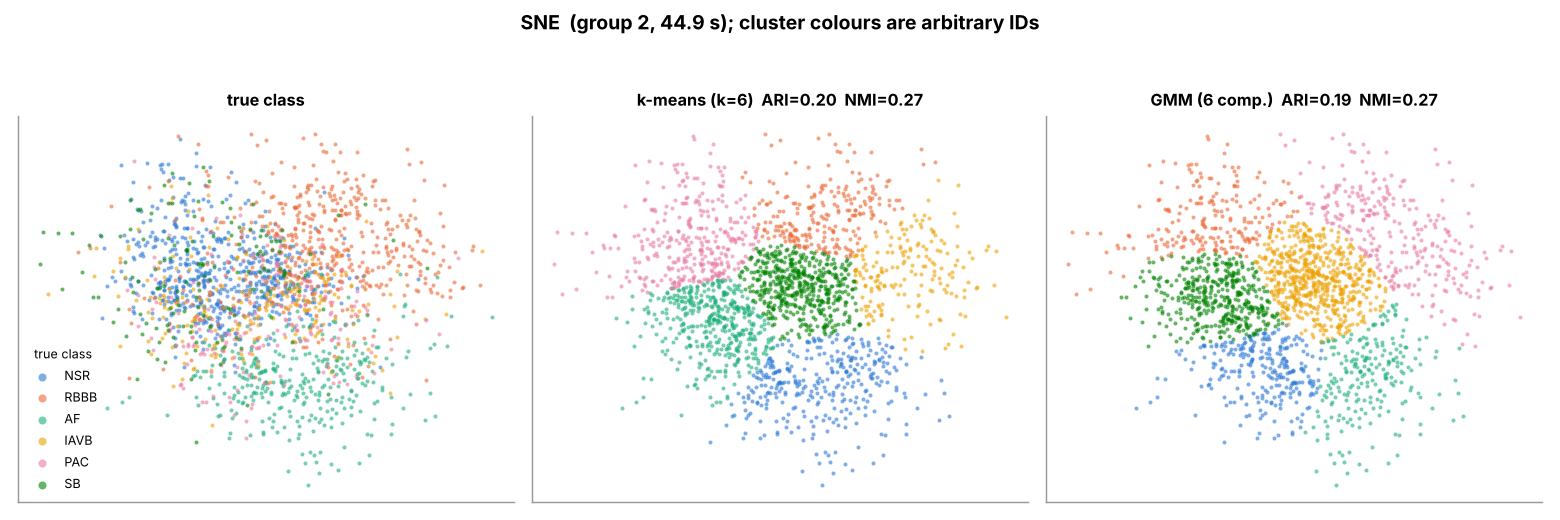

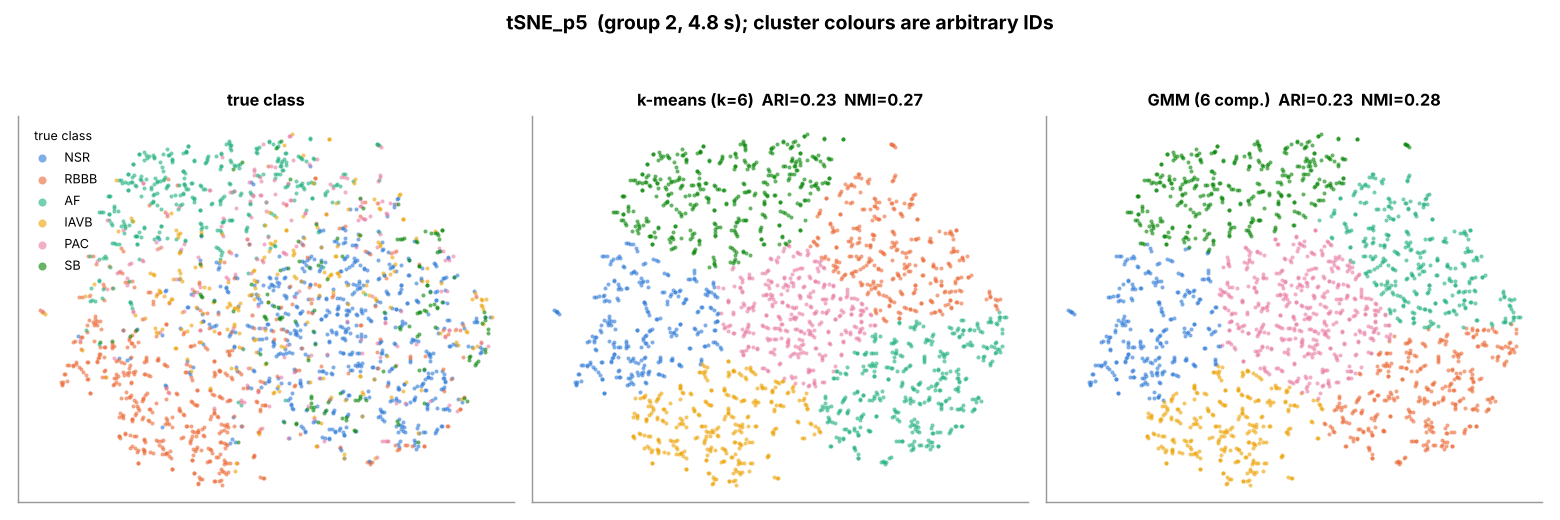

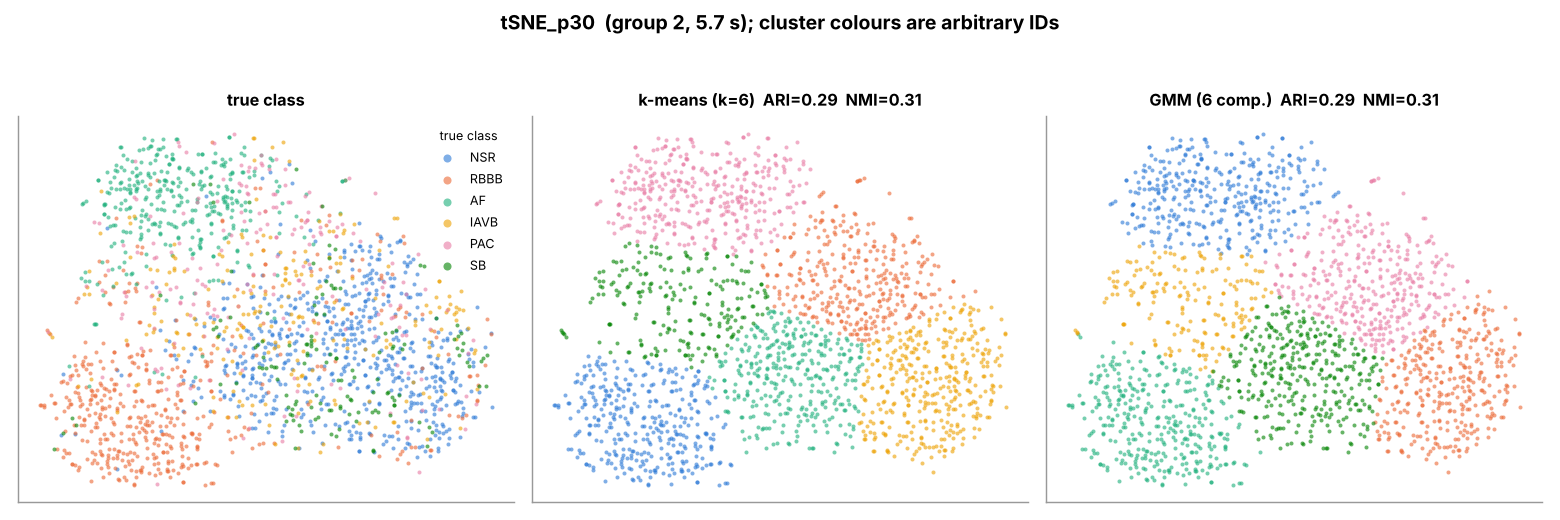

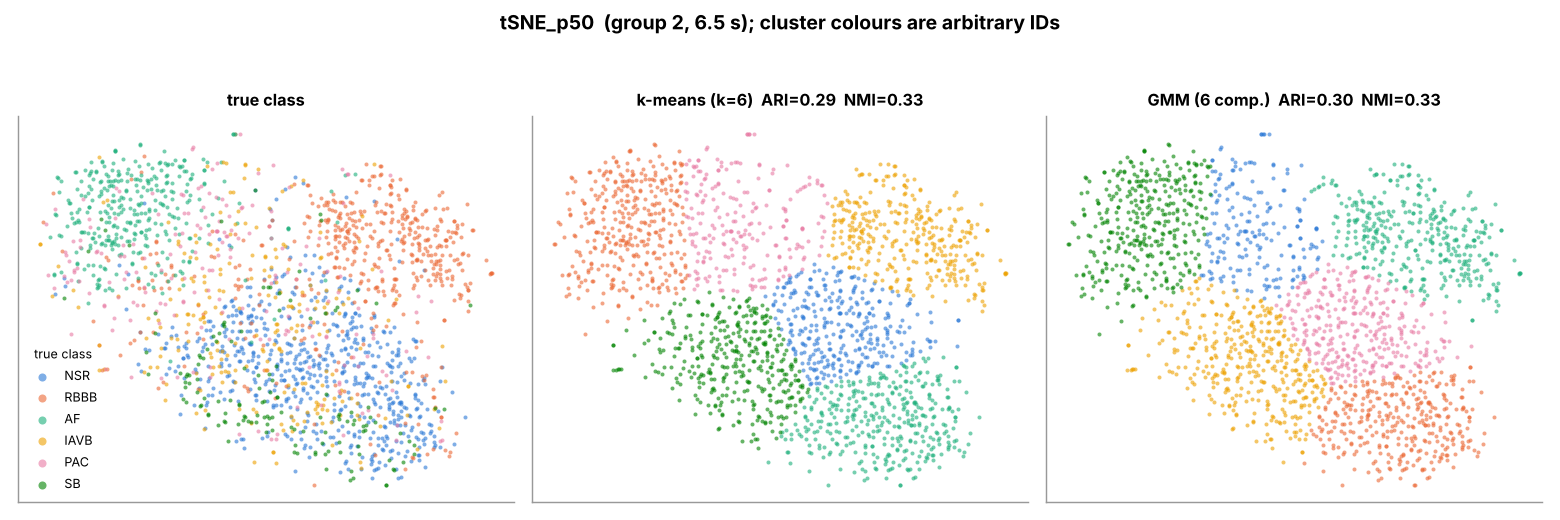

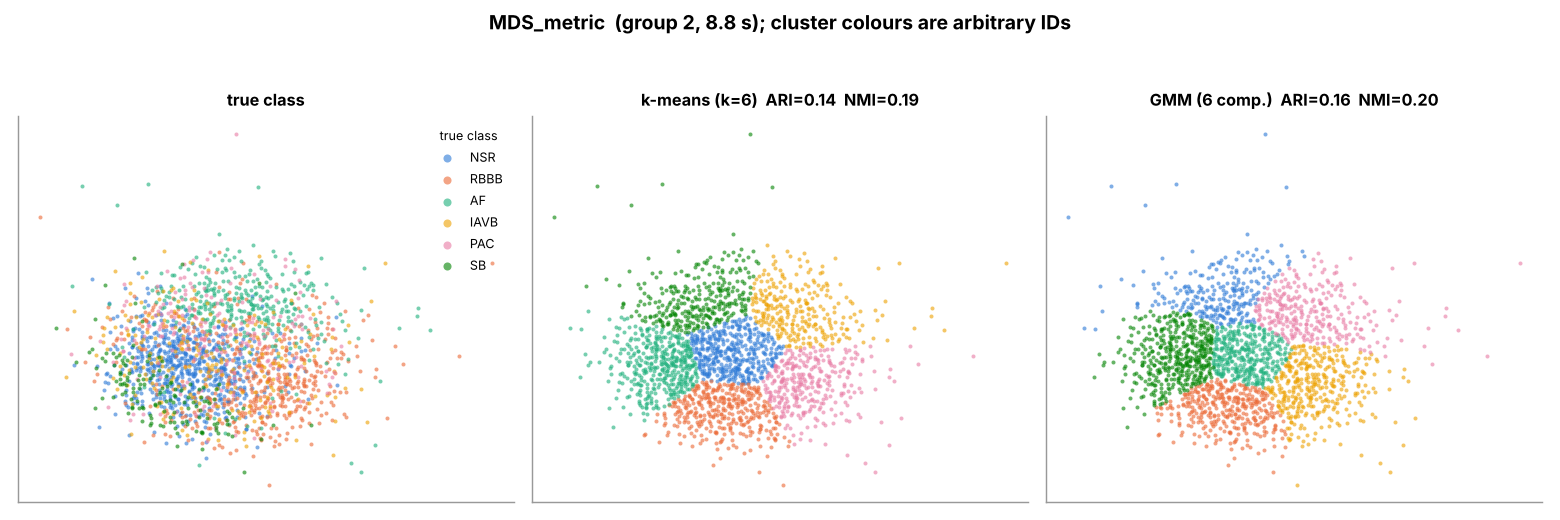

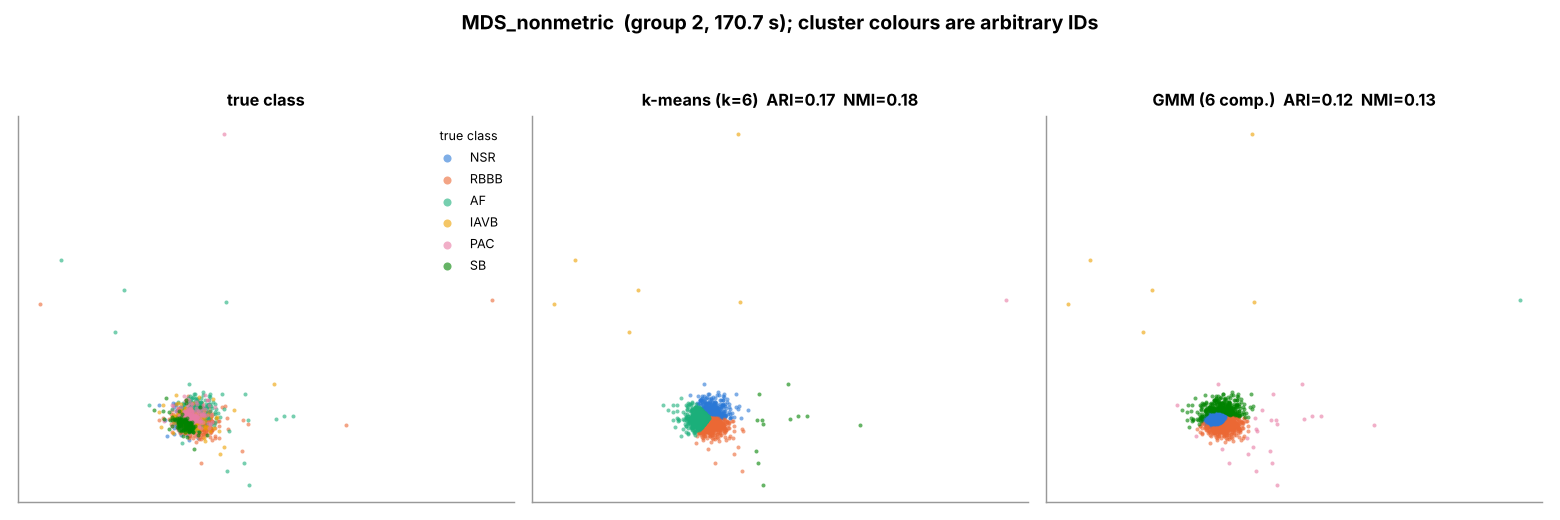

In [8]:
for f in sorted(FIG_DIR.glob("24_*_clusters.png")):
    display(Image(f, width=900))

## 5. SNE from scratch
P: Gaussian conditionals with σᵢ found by binary search so that perplexity = 30. Q: Gaussian, σ = 1/√2. Gradient ∂C/∂yᵢ = 2Σⱼ(pⱼ|ᵢ − qⱼ|ᵢ + pᵢ|ⱼ − qᵢ|ⱼ)(yᵢ − yⱼ); momentum GD with early jitter.

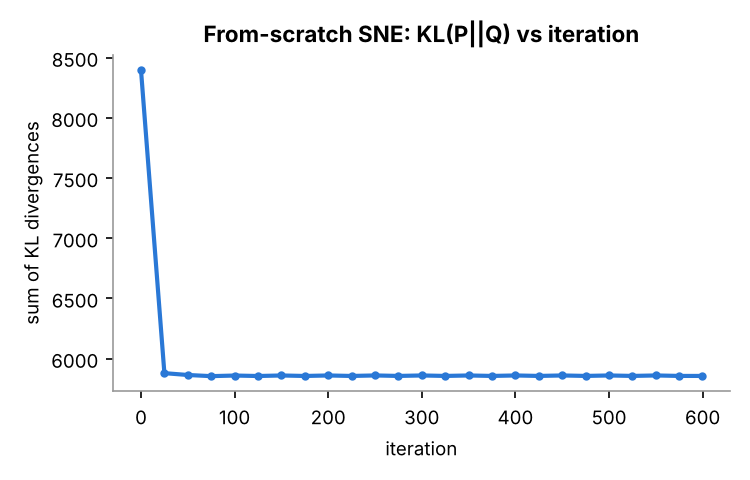

In [9]:
display(Image(FIG_DIR / "26_sne_convergence.png", width=500))

## 6. Hyper-parameter sweeps (plots)

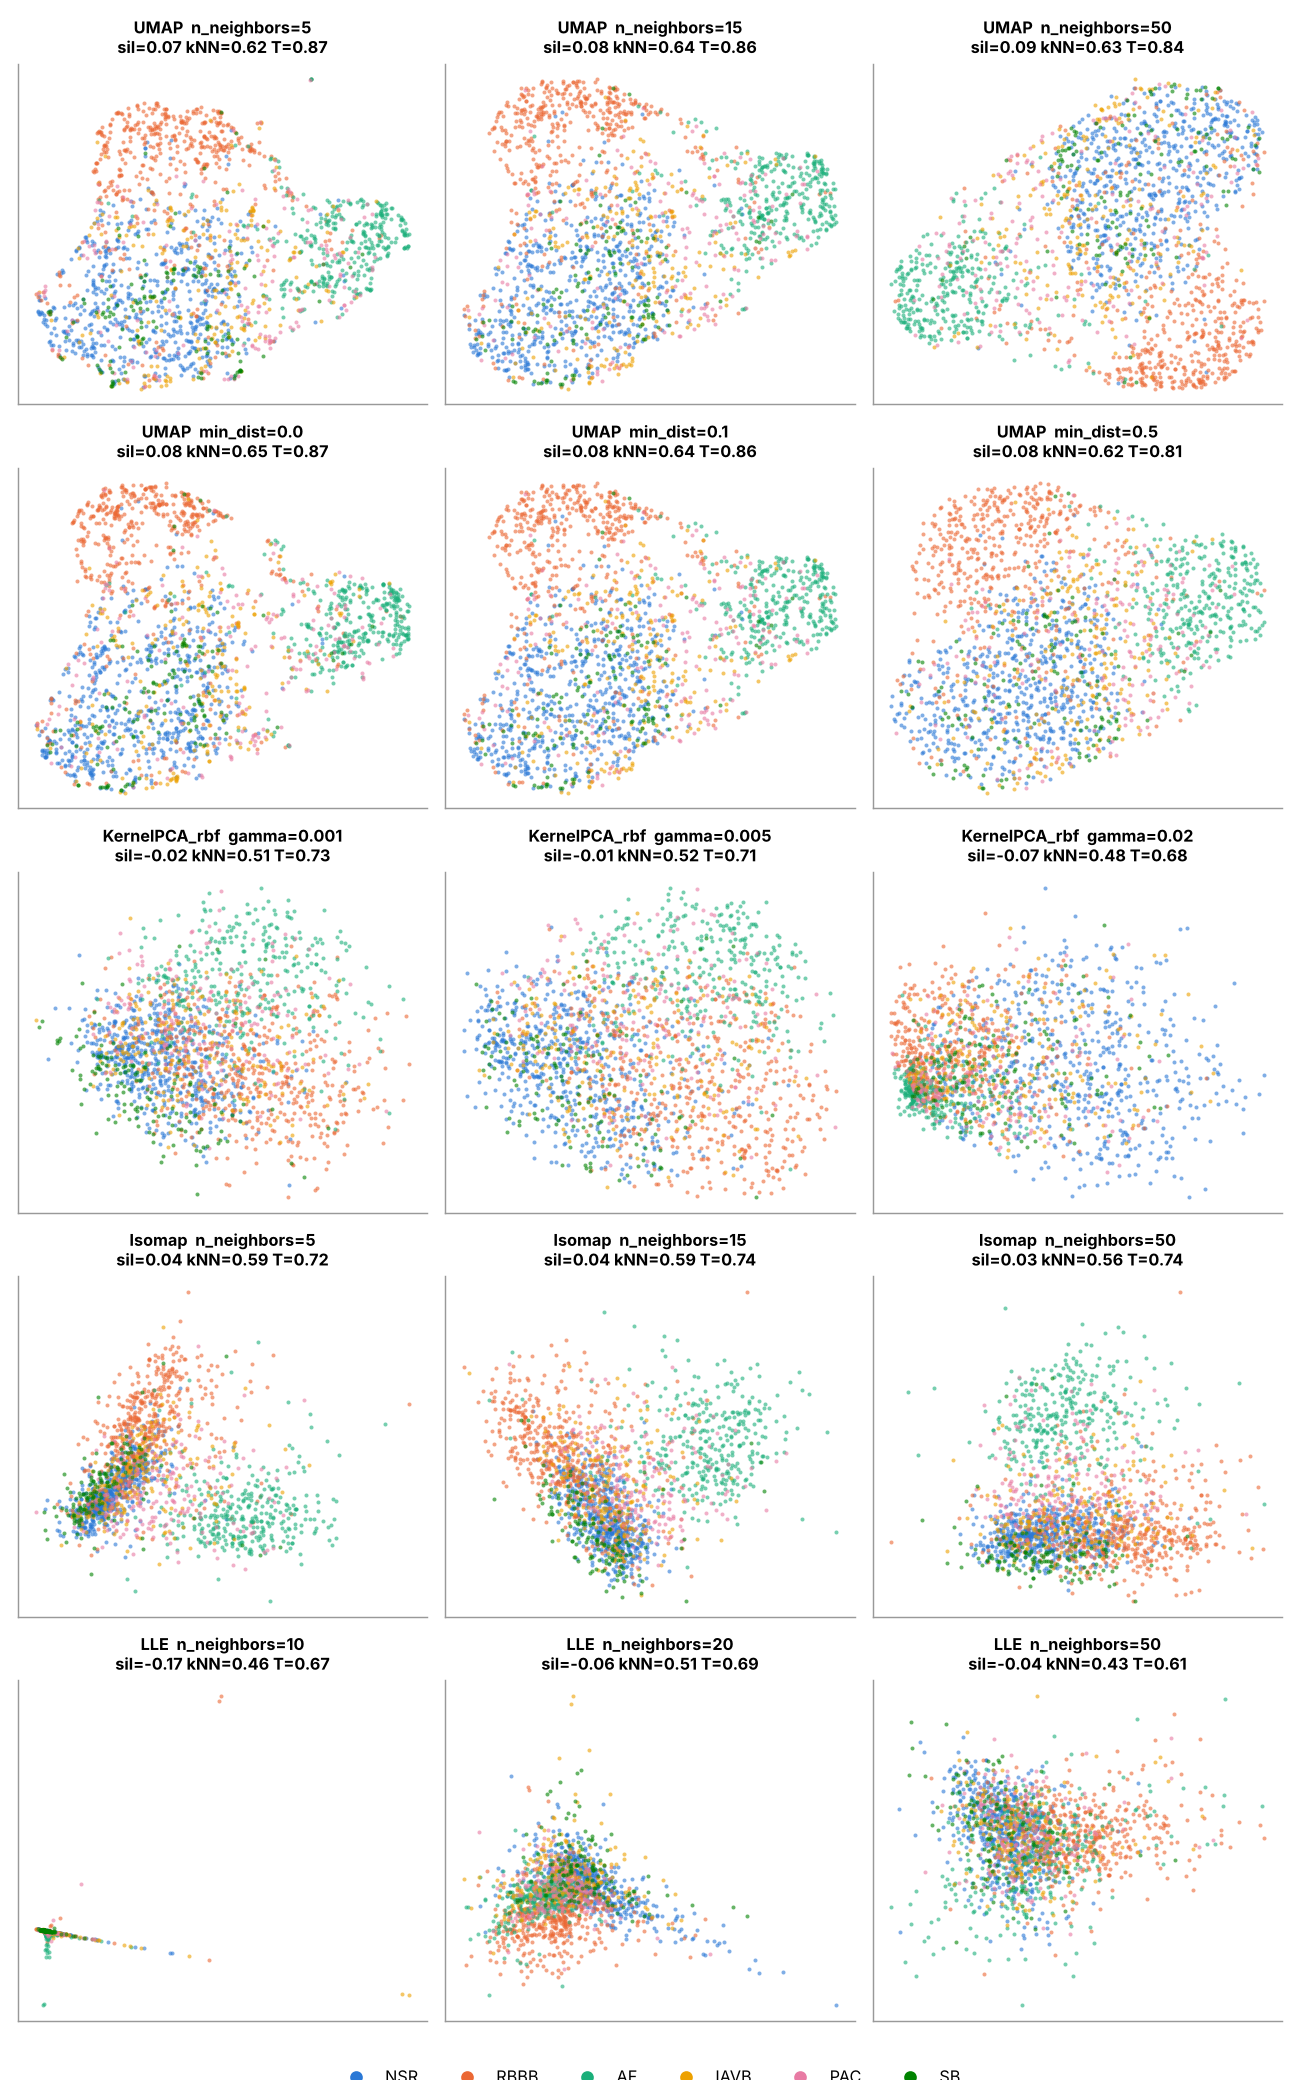

,method,param,value,runtime_s,trustworthiness,silhouette_true,knn_acc_2d,knn_f1_2d,ari_kmeans,nmi_kmeans,ari_gmm,nmi_gmm
0,UMAP,n_neighbors,5.000,1.913,0.873,0.069,0.624,0.494,0.270,0.288,0.237,0.286
1,UMAP,n_neighbors,15.000,2.853,0.860,0.082,0.638,0.501,0.291,0.312,0.259,0.297
2,UMAP,n_neighbors,50.000,4.489,0.842,0.093,0.630,0.477,0.301,0.320,0.279,0.307
3,UMAP,min_dist,0.000,2.901,0.873,0.080,0.649,0.518,0.291,0.313,0.249,0.296
4,UMAP,min_dist,0.100,2.884,0.860,0.082,0.638,0.501,0.291,0.312,0.259,0.297
5,UMAP,min_dist,0.500,2.869,0.807,0.084,0.624,0.472,0.281,0.313,0.280,0.317
6,KernelPCA_rbf,gamma,0.001,0.133,0.727,-0.018,0.508,0.371,0.151,0.198,0.138,0.200
7,KernelPCA_rbf,gamma,0.005,0.148,0.711,-0.015,0.519,0.349,0.169,0.211,0.178,0.227
8,KernelPCA_rbf,gamma,0.020,0.117,0.685,-0.072,0.484,0.313,0.097,0.148,0.110,0.152
9,Isomap,n_neighbors,5.000,0.691,0.719,0.039,0.585,0.447,0.216,0.291,0.234,0.298


In [10]:
display(Image(FIG_DIR / "25_hyperparameter_sweeps.png", width=850)); pd.read_csv(M2 / "sweeps.csv").round(3)

## 7. Downstream classification (group 1 only, reducer inside the pipeline, shared 5 folds)

In [11]:
d = pd.read_csv(M2 / "downstream_cv.csv")
d[["method","dim","clf","f1_macro_val_mean","f1_macro_val_std","accuracy_val_mean","f1_macro_train_mean","gap_f1_macro","flag","fit_s_mean"]].round(3).sort_values("f1_macro_val_mean", ascending=False)

,method,dim,clf,f1_macro_val_mean,f1_macro_val_std,accuracy_val_mean,f1_macro_train_mean,gap_f1_macro,flag,fit_s_mean
66,none,131,lgbm,0.786,0.011,0.818,0.979,0.194,overfit,7.546
2,none,131,svm,0.766,0.011,0.803,0.940,0.174,overfit,3.605
9,LDA,5,logreg,0.763,0.016,0.793,0.792,0.029,ok,0.123
10,LDA,5,knn,0.763,0.006,0.802,1.000,0.237,overfit,0.042
0,none,131,logreg,0.762,0.012,0.795,0.833,0.070,ok,0.281
...,...,...,...,...,...,...,...,...,...,...
59,LLE_modified,2,svm,0.247,0.063,0.398,0.257,0.010,ok,3.057
57,LLE_modified,2,logreg,0.159,0.023,0.350,0.159,-0.000,underfit,6.206
63,LLE_modified,20,logreg,0.139,0.024,0.308,0.134,-0.006,underfit,6.200
65,LLE_modified,20,svm,0.084,0.018,0.247,0.079,-0.005,underfit,4.546


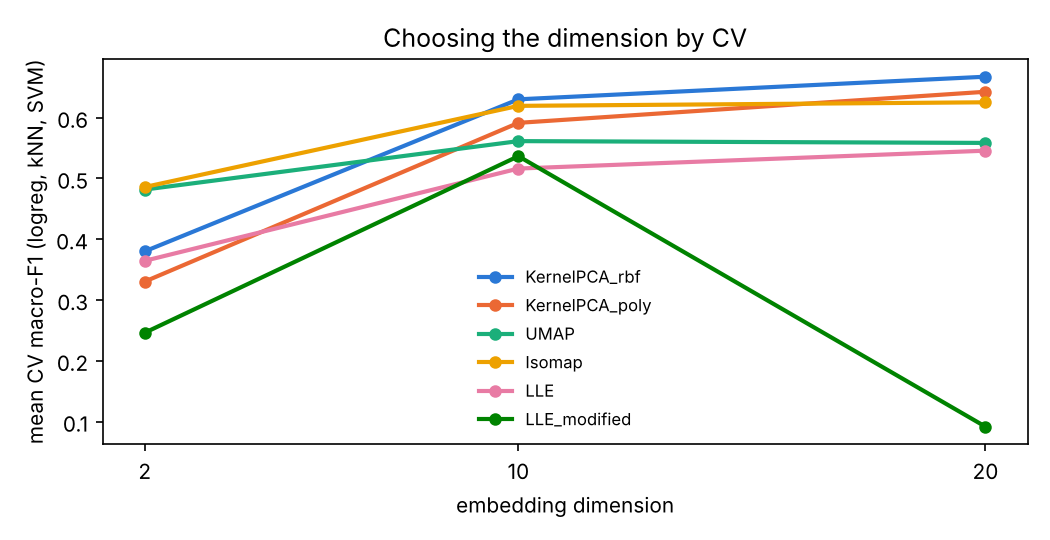

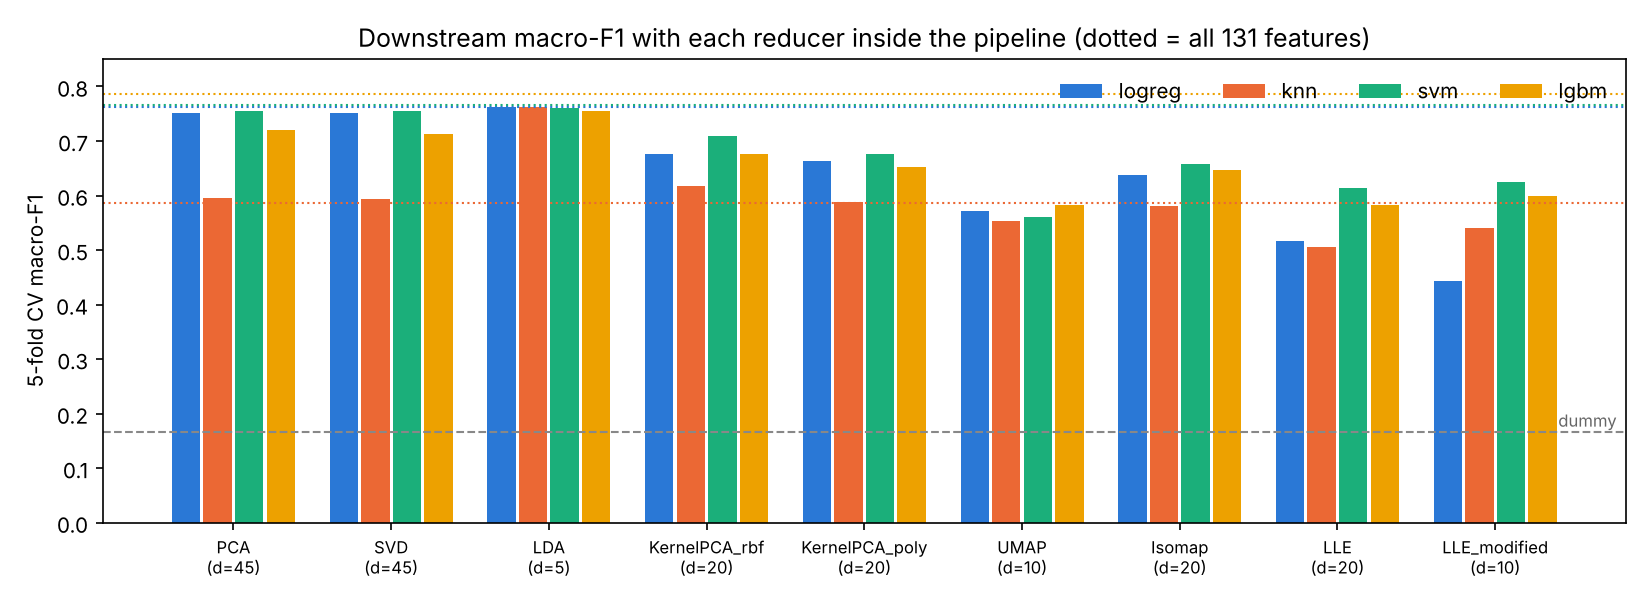

,method,knn,lgbm,logreg,svm,dim,best_f1
0,none,0.586,0.786,0.762,0.766,131,0.786
1,LDA,0.763,0.755,0.763,0.760,5,0.763
2,SVD,0.594,0.712,0.751,0.755,45,0.755
3,PCA,0.595,0.720,0.751,0.755,45,0.755
4,KernelPCA_rbf,0.618,0.676,0.675,0.709,20,0.709
5,KernelPCA_poly,0.588,0.653,0.663,0.677,20,0.677
6,Isomap,0.581,0.647,0.637,0.658,20,0.658
7,LLE_modified,0.541,0.599,0.444,0.625,10,0.625
8,LLE,0.506,0.583,0.517,0.613,20,0.613
9,UMAP,0.553,0.582,0.571,0.560,10,0.582


In [12]:
display(Image(FIG_DIR / "29_dimension_choice.png", width=650)); display(Image(FIG_DIR / "28_downstream_f1.png", width=1000))
pd.read_csv(M2 / "downstream_best_dim.csv").round(3)

## 8. Hand-off to M1

In [13]:
print((M2 / "best_reducer.json").read_text())
from src.reduction import best_reducer
best_reducer()

{
  "best": {
    "method": "LDA",
    "n_components": 5,
    "dim": 5,
    "classifier": "logreg",
    "cv_f1_macro": 0.7628,
    "cv_f1_macro_std": 0.0156,
    "cv_accuracy": 0.793,
    "train_f1_macro": 0.7921,
    "flag": "ok",
    "kwargs": {}
  },
  "parsimonious": {
    "method": "LDA",
    "n_components": 5,
    "dim": 5,
    "classifier": "logreg",
    "cv_f1_macro": 0.7628,
    "cv_f1_macro_std": 0.0156,
    "cv_accuracy": 0.793,
    "train_f1_macro": 0.7921,
    "flag": "ok",
    "kwargs": {}
  },
  "all_features_same_classifiers_cv_f1_macro": 0.7855,
  "usage": "from src.reduction import best_reducer; make_model(clf, params, reducer=best_reducer())",
  "note": "Chosen among runs NOT flagged overfit. kNN uses weights='distance', so its train score is always 1.0 and it is always flagged; LDA+kNN reaches the same 0.763. No reducer beats all 131 features (best 0.786, LightGBM); LDA keeps 97% of that with 5 dimensions instead of 131. Pipeline: impute -> scale -> ClipZ(5) -> LDA(

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clip', ...), ('red', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,c,5.0
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",5
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
